# Teste e Avaliação do Modelo de Deteção de Malware

## Objetivo

Medir como o modelo **Extra Trees**, treinado no notebook `treino_modelo.ipynb`, se comporta em amostras que não foram usadas para o ajustar. Este notebook carrega o modelo e a partição de teste guardada; **não treina nem modifica o modelo**.

**Ordem de execução:** executar primeiro `treino_modelo.ipynb` até ao fim; depois executar este notebook pela ordem apresentada. O conjunto de teste tem 20% dos dados e mantém a estratificação das classes.

## 1. Bibliotecas, localização e verificação dos artefactos

Antes de avaliar, verificamos se o notebook de treino já gerou o modelo e o CSV de teste. Se algum faltar, a mensagem indica qual notebook executar.

In [1]:
from pathlib import Path
import sys

import joblib
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

PROJECT_ROOT = Path("..").resolve()
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from app_paths import MODEL_OUTPUT, RESULTS, ensure_output_dirs
from data_preprocessing import TARGET, compute_classification_metrics

ensure_output_dirs()
test_path = RESULTS / "malware_test_split.csv"
if not test_path.exists():
    raise FileNotFoundError(
        "Não existe a partição de teste. Execute primeiro o notebook treino_modelo.ipynb."
    )
if not MODEL_OUTPUT.exists():
    raise FileNotFoundError(
        "Não existe um modelo treinado. Execute primeiro o notebook treino_modelo.ipynb."
    )

print("Ficheiro de teste:", test_path)
print("Modelo treinado:", MODEL_OUTPUT)

Ficheiro de teste: C:\Users\istec\Documents\malware-detection-ml-final-clean\malware-detection-ml-final-clean\results\malware_test_split.csv
Modelo treinado: C:\Users\istec\Documents\malware-detection-ml-final-clean\malware-detection-ml-final-clean\models\modelo_extra_trees.joblib


## 2. Carregamento do modelo e dos dados reservados

Carregamos o modelo guardado e a partição de teste criada pelo notebook de treino. A coluna `Malicious` fornece a resposta verdadeira para comparar com as previsões; não é fornecida como entrada ao classificador.

In [2]:
test_df = pd.read_csv(test_path)
y_test = pd.to_numeric(test_df.pop(TARGET), errors="raise").astype(int)
X_test = test_df
model = joblib.load(MODEL_OUTPUT)

print("Amostras reservadas para teste:", len(X_test))
print("Features usadas:", X_test.shape[1])

Amostras reservadas para teste: 232
Features usadas: 28


## 3. Previsões e métricas de avaliação

Aplicamos `predict` e `predict_proba` às features do teste. A accuracy mede os acertos globais; precision indica a fiabilidade das previsões positivas; recall mede a proporção de malware detetado; F1 equilibra precision e recall; ROC-AUC mede a separação das classes pelas probabilidades.

Em deteção de malware, um falso negativo é malware classificado como benigno, por isso o recall da classe Malware merece atenção. Nenhuma métrica, isoladamente, certifica a segurança dos ficheiros.

In [3]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]
metrics = compute_classification_metrics(y_test, y_pred, y_probability)

print(f"Amostras avaliadas: {len(y_test)}")
print("\nMétricas no conjunto de teste:")
for metric_name, value in metrics.items():
    print(f"{metric_name}: {value:.2%}")

print("\nRelatório por classe:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Benigno", "Malware"],
    digits=3,
    zero_division=0,
))

Amostras avaliadas: 232

Métricas no conjunto de teste:
Accuracy: 97.41%
Precision: 95.80%
Recall: 99.13%
F1: 97.44%
ROC-AUC: 99.73%

Relatório por classe:
              precision    recall  f1-score   support

     Benigno      0.991     0.957     0.974       117
     Malware      0.958     0.991     0.974       115

    accuracy                          0.974       232
   macro avg      0.975     0.974     0.974       232
weighted avg      0.975     0.974     0.974       232



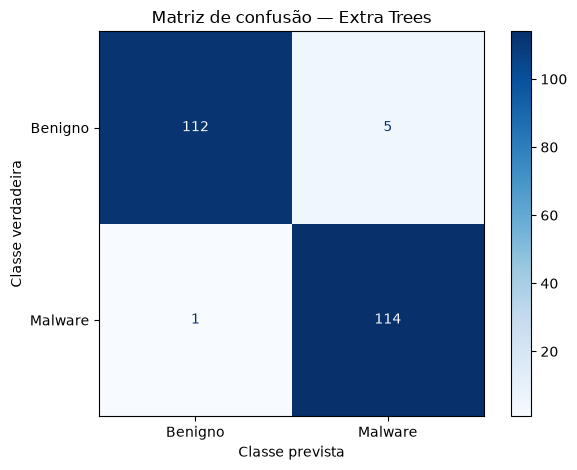

Métricas guardadas em: C:\Users\istec\Documents\malware-detection-ml-final-clean\malware-detection-ml-final-clean\results\model_metrics_notebook_test.csv


In [4]:
metrics_path = RESULTS / "model_metrics_notebook_test.csv"
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Benigno", "Malware"],
    cmap="Blues",
    values_format="d",
)
plt.title("Matriz de confusão — Extra Trees")
plt.xlabel("Classe prevista")
plt.ylabel("Classe verdadeira")
plt.tight_layout()
plt.show()

print("Métricas guardadas em:", metrics_path)